# Complete EDA: Himalayan Expeditions

**Files:** `peaks.csv`, `expeditions.csv`, `members.csv` (place them in the same folder as this notebook).

**Outline**
1. Load & overview
2. Data quality checks
3. Cleaning
4. Peaks
5. Expeditions
6. Members
7. Trends over time
8. Risk & safety
9. Cross-table analysis (peak height, oxygen)
10. Correlations
11. Everest deep dive
12. Key findings

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid')
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)

## 1. Load & overview

In [2]:
peaks = pd.read_csv('peaks.csv')
exp = pd.read_csv('expeditions.csv', parse_dates=['basecamp_date', 'highpoint_date', 'termination_date'])
mem = pd.read_csv('members.csv')

summary = pd.DataFrame({
    'rows': [len(peaks), len(exp), len(mem)],
    'columns': [peaks.shape[1], exp.shape[1], mem.shape[1]],
    'duplicate_rows': [peaks.duplicated().sum(), exp.duplicated().sum(), mem.duplicated().sum()],
}, index=['peaks', 'expeditions', 'members'])
summary

,rows,columns,duplicate_rows
peaks,468,8,0
expeditions,10364,16,0
members,76519,21,0


In [3]:
peaks.head()

,peak_id,peak_name,peak_alternative_name,height_metres,climbing_status,first_ascent_year,first_ascent_country,first_ascent_expedition_id
0,AMAD,Ama Dablam,Amai Dablang,6814,Climbed,1961.0,"New Zealand, USA, UK",AMAD61101
1,AMPG,Amphu Gyabjen,NaN,5630,Climbed,1953.0,UK,AMPG53101
2,ANN1,Annapurna I,NaN,8091,Climbed,1950.0,France,ANN150101
3,ANN2,Annapurna II,NaN,7937,Climbed,1960.0,"UK, Nepal",ANN260101
4,ANN3,Annapurna III,NaN,7555,Climbed,1961.0,India,ANN361101


In [4]:
exp.head()

,expedition_id,peak_id,peak_name,year,season,basecamp_date,highpoint_date,termination_date,termination_reason,highpoint_metres,members,member_deaths,hired_staff,hired_staff_deaths,oxygen_used,trekking_agency
0,ANN260101,ANN2,Annapurna II,1960,Spring,1960-03-15,1960-05-17,NaT,Success (main peak),7937.0,10,0,9,0,True,NaN
1,ANN269301,ANN2,Annapurna II,1969,Autumn,1969-09-25,1969-10-22,1969-10-26,Success (main peak),7937.0,10,0,0,0,False,NaN
2,ANN273101,ANN2,Annapurna II,1973,Spring,1973-03-16,1973-05-06,NaT,Success (main peak),7937.0,6,0,8,0,False,NaN
3,ANN278301,ANN2,Annapurna II,1978,Autumn,1978-09-08,1978-10-02,1978-10-05,"Bad weather (storms, high winds)",7000.0,2,0,0,0,False,NaN
4,ANN279301,ANN2,Annapurna II,1979,Autumn,NaT,1979-10-18,1979-10-20,"Bad weather (storms, high winds)",7160.0,3,0,0,0,False,NaN


In [5]:
mem.head()

,expedition_id,member_id,peak_id,peak_name,year,season,sex,age,citizenship,expedition_role,hired,highpoint_metres,success,solo,oxygen_used,died,death_cause,death_height_metres,injured,injury_type,injury_height_metres
0,AMAD78301,AMAD78301-01,AMAD,Ama Dablam,1978,Autumn,M,40.0,France,Leader,False,NaN,False,False,False,False,NaN,NaN,False,NaN,NaN
1,AMAD78301,AMAD78301-02,AMAD,Ama Dablam,1978,Autumn,M,41.0,France,Deputy Leader,False,6000.0,False,False,False,False,NaN,NaN,False,NaN,NaN
2,AMAD78301,AMAD78301-03,AMAD,Ama Dablam,1978,Autumn,M,27.0,France,Climber,False,NaN,False,False,False,False,NaN,NaN,False,NaN,NaN
3,AMAD78301,AMAD78301-04,AMAD,Ama Dablam,1978,Autumn,M,40.0,France,Exp Doctor,False,6000.0,False,False,False,False,NaN,NaN,False,NaN,NaN
4,AMAD78301,AMAD78301-05,AMAD,Ama Dablam,1978,Autumn,M,34.0,France,Climber,False,NaN,False,False,False,False,NaN,NaN,False,NaN,NaN


In [6]:
# column types, missing values and unique counts for each table
def profile(df):
    return pd.DataFrame({
        'dtype': df.dtypes.astype(str),
        'missing': df.isna().sum(),
        'missing_%': (df.isna().mean() * 100).round(1),
        'unique': df.nunique(),
    })

print('PEAKS');       display(profile(peaks))
print('EXPEDITIONS'); display(profile(exp))
print('MEMBERS');     display(profile(mem))

PEAKS


,dtype,missing,missing_%,unique
peak_id,str,0,0.0,468
peak_name,str,0,0.0,468
peak_alternative_name,str,223,47.6,242
height_metres,int64,0,0.0,407
climbing_status,str,0,0.0,2
first_ascent_year,float64,132,28.2,70
first_ascent_country,str,132,28.2,77
first_ascent_expedition_id,str,135,28.8,332


EXPEDITIONS


,dtype,missing,missing_%,unique
expedition_id,str,0,0.0,10363
peak_id,str,0,0.0,391
peak_name,str,1,0.0,390
year,int64,0,0.0,92
season,str,0,0.0,5
basecamp_date,datetime64[us],1095,10.6,4180
highpoint_date,datetime64[us],650,6.3,3919
termination_date,datetime64[us],2380,23.0,3266
termination_reason,str,0,0.0,15
highpoint_metres,float64,414,4.0,694


MEMBERS


,dtype,missing,missing_%,unique
expedition_id,str,0,0.0,10350
member_id,str,0,0.0,76518
peak_id,str,0,0.0,391
peak_name,str,15,0.0,390
year,int64,0,0.0,92
season,str,0,0.0,5
sex,str,2,0.0,2
age,float64,3497,4.6,74
citizenship,str,10,0.0,212
expedition_role,str,21,0.0,524


In [7]:
# numeric summary statistics
display(peaks.describe().round(1))
display(exp.describe().round(1))
display(mem.describe().round(1))

,height_metres,first_ascent_year
count,468.0,336.0
mean,6656.6,1979.1
std,571.9,100.2
min,5407.0,201.0
25%,6235.8,1963.0
50%,6559.5,1982.0
75%,6911.0,2008.0
max,8850.0,2019.0


,year,basecamp_date,highpoint_date,termination_date,highpoint_metres,members,member_deaths,hired_staff,hired_staff_deaths
count,10364.0,9269,9714,7984,9950.0,10364.0,10364.0,10364.0,10364.0
mean,2001.2,2002-02-19 00:10:15.211997,2002-04-09 19:27:58.814082,2004-01-06 02:13:38.837675,7408.9,6.0,0.1,2.8,0.0
min,1905.0,1921-06-26 00:00:00,1905-09-01 00:00:00,1921-09-30 00:00:00,3500.0,0.0,0.0,0.0,0.0
25%,1994.0,1994-11-25 00:00:00,1995-02-03 00:00:00,1998-10-19 00:00:00,6700.0,2.0,0.0,0.0,0.0
50%,2005.0,2005-04-15 00:00:00,2005-09-26 00:00:00,2006-10-03 00:00:00,7300.0,5.0,0.0,1.0,0.0
75%,2012.0,2011-05-15 00:00:00,2011-11-16 18:00:00,2012-05-07 06:00:00,8188.0,8.0,0.0,3.0,0.0
max,2019.0,2019-05-27 00:00:00,2019-05-30 00:00:00,2019-06-04 00:00:00,8850.0,99.0,10.0,99.0,11.0
std,14.7,NaN,NaN,NaN,1012.6,5.4,0.4,5.1,0.3


,year,age,highpoint_metres,death_height_metres,injury_height_metres
count,76519.0,73022.0,54686.0,1068.0,1009.0
mean,2000.4,37.3,7470.7,6592.9,7049.9
std,14.8,10.4,1040.1,1308.2,1214.2
min,1905.0,7.0,3800.0,400.0,400.0
25%,1991.0,29.0,6700.0,5800.0,6200.0
50%,2004.0,36.0,7400.0,6600.0,7100.0
75%,2012.0,44.0,8400.0,7550.0,8000.0
max,2019.0,85.0,8850.0,8830.0,8880.0


## 2. Data quality checks
Looking for duplicate keys, broken links between tables, impossible values and inconsistencies.

In [8]:
print('Duplicate expedition_id values   :', exp.expedition_id.duplicated().sum())
print('Duplicate member_id values       :', mem.member_id.duplicated().sum())
print('Duplicate peak_id values         :', peaks.peak_id.duplicated().sum())
print()
print('Peak IDs in expeditions but not in peaks:', sorted(set(exp.peak_id) - set(peaks.peak_id)))
print('Expedition IDs in members but not in expeditions:', len(set(mem.expedition_id) - set(exp.expedition_id)))
print()
print('Expeditions with 0 members      :', (exp.members == 0).sum())
print('Expeditions with >= 50 members  :', (exp.members >= 50).sum())
print('Members aged under 12           :', (mem.age < 12).sum())
print('Members aged over 75            :', (mem.age > 75).sum())
print('Peaks with first ascent < 1800  :', peaks.loc[peaks.first_ascent_year < 1800, 'peak_name'].tolist())

exp[exp.expedition_id.duplicated(keep=False)][['expedition_id', 'peak_name', 'year', 'termination_reason', 'members']]

Duplicate expedition_id values   : 1
Duplicate member_id values       : 1
Duplicate peak_id values         : 0

Peak IDs in expeditions but not in peaks: ['SPHU']


Expedition IDs in members but not in expeditions: 0

Expeditions with 0 members      : 48
Expeditions with >= 50 members  : 9
Members aged under 12           : 1
Members aged over 75            : 36
Peaks with first ascent < 1800  : ['Sharphu II']


,expedition_id,peak_name,year,termination_reason,members
2883,KANG10101,Kangchenjunga,1910,Did not attempt climb,1
6819,KANG10101,Kangchenjunga,2010,Success (main peak),4


In [9]:
# does the expedition table agree with the members table?
check = mem.groupby('expedition_id').agg(rows=('member_id', 'size'), deaths=('died', 'sum'))
check = check.join(exp.drop_duplicates('expedition_id').set_index('expedition_id')[['members', 'hired_staff', 'member_deaths', 'hired_staff_deaths']])

print('Headcount matches member rows :', f"{(check.rows == check.members + check.hired_staff).mean():.1%}")
print('Death counts match            :', f"{(check.deaths == check.member_deaths + check.hired_staff_deaths).mean():.1%}")

# highpoint above the peak's listed height
x = exp.merge(peaks[['peak_id', 'height_metres']], on='peak_id')
print('Highpoint > peak height + 50m :', (x.highpoint_metres > x.height_metres + 50).sum())

Headcount matches member rows : 66.4%
Death counts match            : 100.0%
Highpoint > peak height + 50m : 11


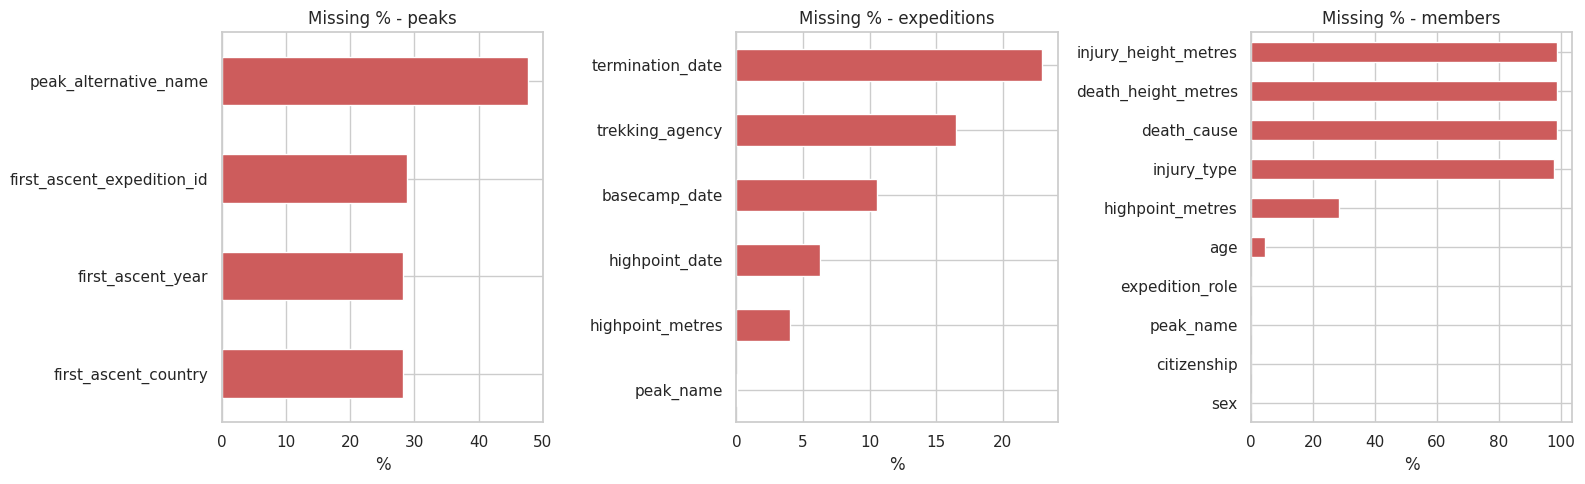

In [10]:
# missing values chart
miss = pd.concat([
    (exp.isna().mean() * 100).rename('expeditions'),
    (mem.isna().mean() * 100).rename('members'),
    (peaks.isna().mean() * 100).rename('peaks'),
], axis=1)
fig, ax = plt.subplots(1, 3, figsize=(16, 5))
for a, (name, df) in zip(ax, [('peaks', peaks), ('expeditions', exp), ('members', mem)]):
    s = (df.isna().mean() * 100).sort_values()
    s = s[s > 0]
    s.plot.barh(ax=a, color='indianred')
    a.set(title=f'Missing % - {name}', xlabel='%')
plt.tight_layout(); plt.show()

## 3. Cleaning
Simple, transparent fixes so the rest of the analysis is reliable. Original data is kept; we work on cleaned copies.

In [11]:
# peaks: set the impossible first-ascent year (201) to missing
peaks_c = peaks.copy()
peaks_c.loc[peaks_c.first_ascent_year < 1800, 'first_ascent_year'] = np.nan

# expeditions: make a unique key (expedition_id is reused for 1910 and 2010), flag success, add duration
exp_c = exp.copy()
exp_c['exp_key'] = exp_c.expedition_id + '_' + exp_c.year.astype(str)
exp_c['success'] = exp_c.termination_reason.str.startswith('Success')
exp_c['duration_days'] = (exp_c.termination_date - exp_c.basecamp_date).dt.days
exp_c['decade'] = (exp_c.year // 10) * 10
exp_c['total_team'] = exp_c.members + exp_c.hired_staff
exp_c['peak_name'] = exp_c.peak_name.fillna('Unknown (SPHU)')

# members: tidy ages (keep as-is, flag implausible)
mem_c = mem.copy()
mem_c['age_group'] = pd.cut(mem_c.age, [0, 20, 30, 40, 50, 60, 100], labels=['<20', '20-29', '30-39', '40-49', '50-59', '60+'])
mem_c['decade'] = (mem_c.year // 10) * 10

print('Cleaned. Expeditions (unique):', exp_c.exp_key.nunique(), '| Members:', len(mem_c))

Cleaned. Expeditions (unique): 10364 | Members: 76519


## 4. Peaks

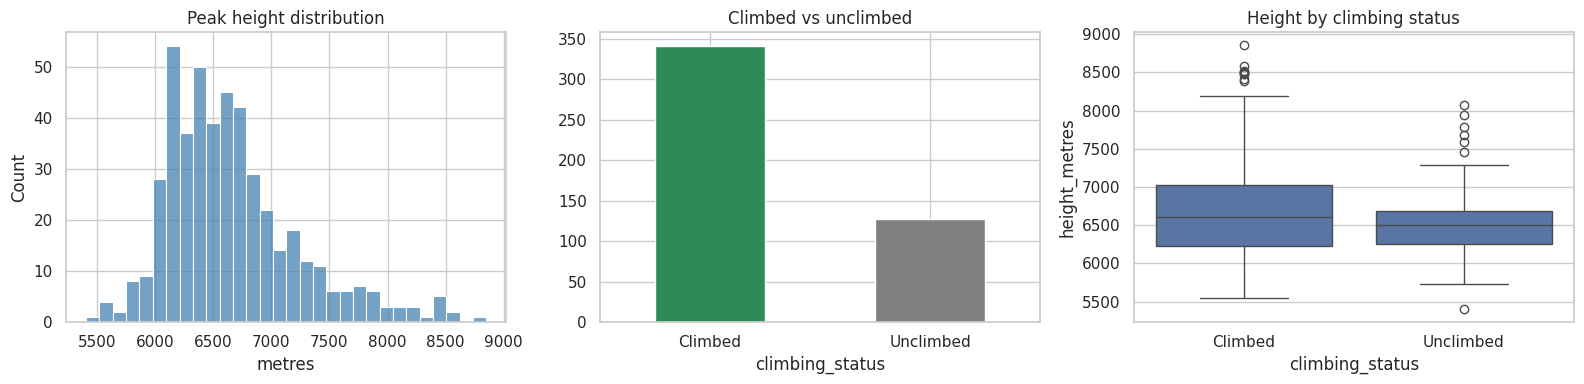

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(peaks_c.height_metres, bins=30, ax=ax[0], color='steelblue')
ax[0].set(title='Peak height distribution', xlabel='metres')
peaks_c.climbing_status.value_counts().plot.bar(ax=ax[1], color=['seagreen', 'gray'], rot=0)
ax[1].set(title='Climbed vs unclimbed')
sns.boxplot(data=peaks_c, x='climbing_status', y='height_metres', ax=ax[2])
ax[2].set(title='Height by climbing status')
plt.tight_layout(); plt.show()

In [13]:
display(peaks_c.nlargest(10, 'height_metres')[['peak_name', 'height_metres', 'climbing_status', 'first_ascent_year', 'first_ascent_country']])
print('Number of 8000m+ peaks:', (peaks_c.height_metres >= 8000).sum())

,peak_name,height_metres,climbing_status,first_ascent_year,first_ascent_country
42,Everest,8850,Climbed,1953.0,"New Zealand, India"
91,Kangchenjunga,8586,Climbed,1955.0,UK
112,Lhotse,8516,Climbed,1956.0,Switzerland
188,Yalung Kang,8505,Climbed,1973.0,Japan
122,Makalu,8485,Climbed,1955.0,France
92,Kangchenjunga South,8476,Climbed,1978.0,Poland
89,Kangchenjunga Central,8473,Climbed,1978.0,Poland
205,Lhotse Middle,8410,Climbed,2001.0,Russia
117,Lhotse Shar,8382,Climbed,1970.0,Austria
20,Cho Oyu,8188,Climbed,1954.0,"Austria, Nepal"


Number of 8000m+ peaks: 16


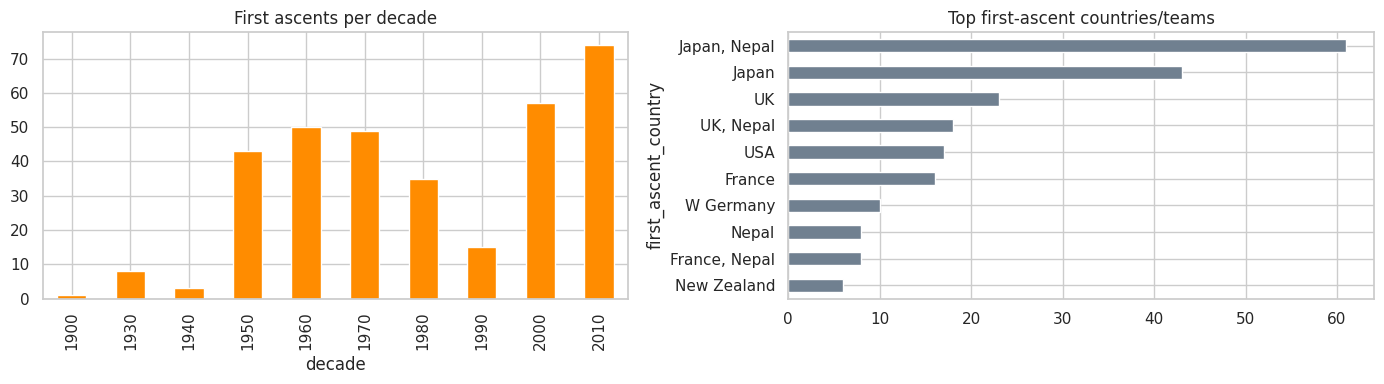

In [14]:
fa = peaks_c.dropna(subset=['first_ascent_year']).copy()
fa['period'] = (fa.first_ascent_year // 10 * 10).astype(int)
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
fa[fa.first_ascent_year >= 1900].groupby('period').size().plot.bar(ax=ax[0], color='darkorange')
ax[0].set(title='First ascents per decade', xlabel='decade')
peaks_c.first_ascent_country.value_counts().head(10).sort_values().plot.barh(ax=ax[1], color='slategray')
ax[1].set(title='Top first-ascent countries/teams')
plt.tight_layout(); plt.show()

## 5. Expeditions

In [15]:
print('Overall success rate:', round(exp_c.success.mean(), 3))
exp_c[['members', 'hired_staff', 'total_team', 'member_deaths', 'highpoint_metres', 'duration_days']].describe().round(1)

Overall success rate: 0.553


,members,hired_staff,total_team,member_deaths,highpoint_metres,duration_days
count,10364.0,10364.0,10364.0,10364.0,9950.0,7946.0
mean,6.0,2.8,8.7,0.1,7408.9,26.6
std,5.4,5.1,9.2,0.4,1012.6,15.4
min,0.0,0.0,0.0,0.0,3500.0,0.0
25%,2.0,0.0,3.0,0.0,6700.0,14.0
50%,5.0,1.0,6.0,0.0,7300.0,25.0
75%,8.0,3.0,11.0,0.0,8188.0,37.0
max,99.0,99.0,198.0,10.0,8850.0,133.0


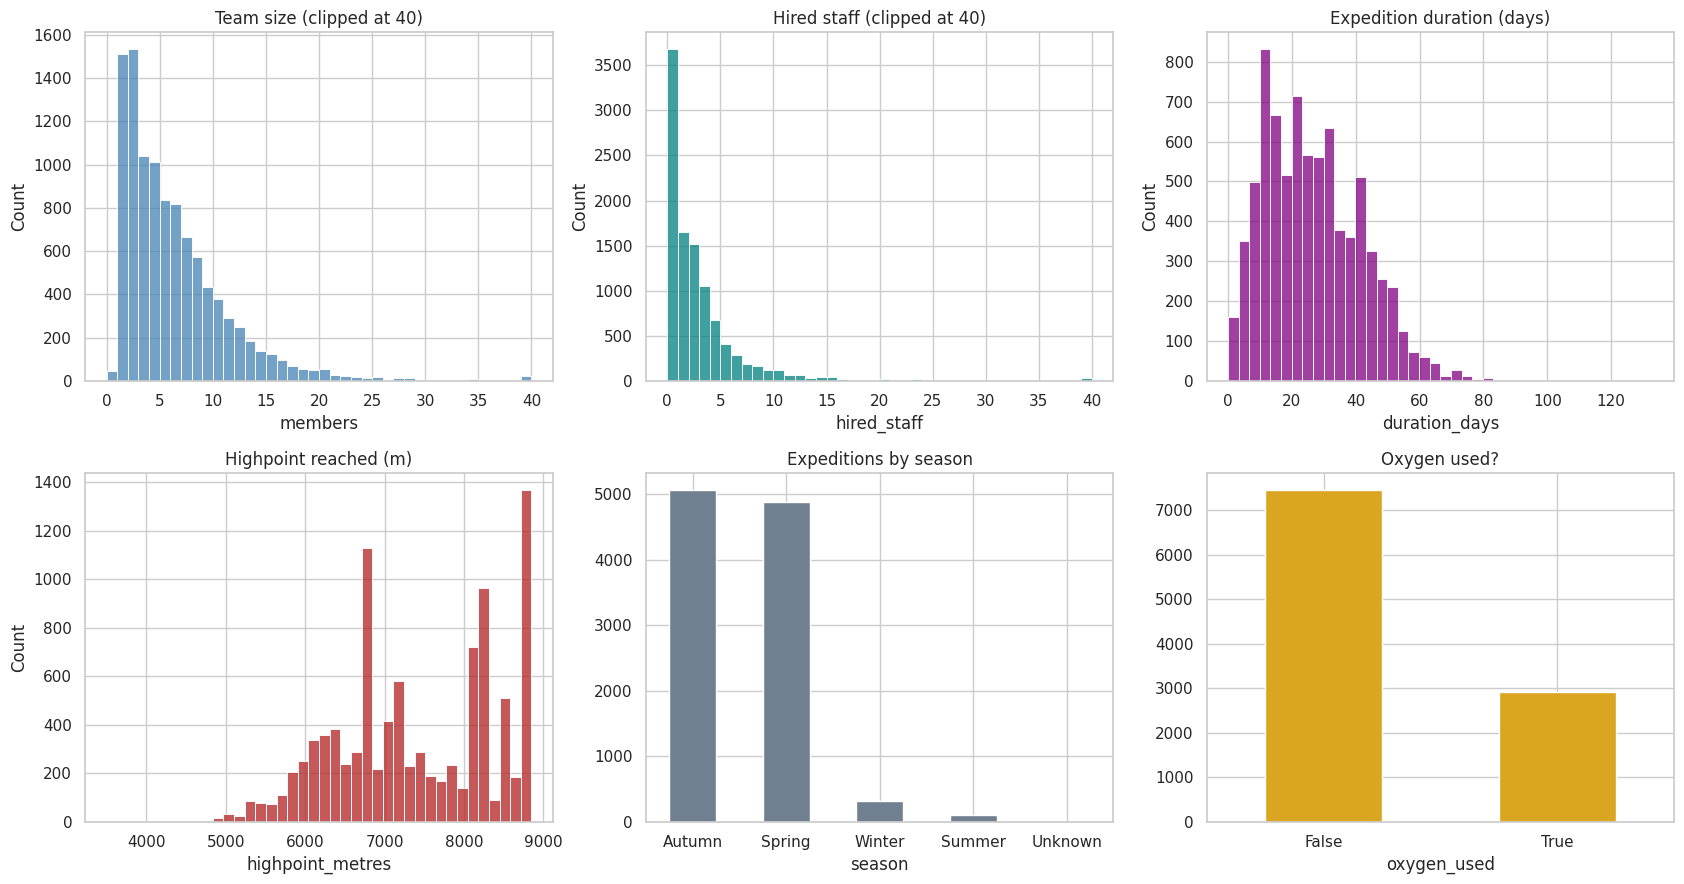

In [16]:
fig, ax = plt.subplots(2, 3, figsize=(17, 9))
sns.histplot(exp_c.members.clip(upper=40), bins=40, ax=ax[0, 0], color='steelblue'); ax[0, 0].set(title='Team size (clipped at 40)')
sns.histplot(exp_c.hired_staff.clip(upper=40), bins=40, ax=ax[0, 1], color='teal'); ax[0, 1].set(title='Hired staff (clipped at 40)')
sns.histplot(exp_c.duration_days.dropna(), bins=40, ax=ax[0, 2], color='purple'); ax[0, 2].set(title='Expedition duration (days)')
sns.histplot(exp_c.highpoint_metres.dropna(), bins=40, ax=ax[1, 0], color='firebrick'); ax[1, 0].set(title='Highpoint reached (m)')
exp_c.season.value_counts().plot.bar(ax=ax[1, 1], rot=0, color='slategray'); ax[1, 1].set(title='Expeditions by season')
exp_c.oxygen_used.value_counts().plot.bar(ax=ax[1, 2], rot=0, color='goldenrod'); ax[1, 2].set(title='Oxygen used?')
plt.tight_layout(); plt.show()

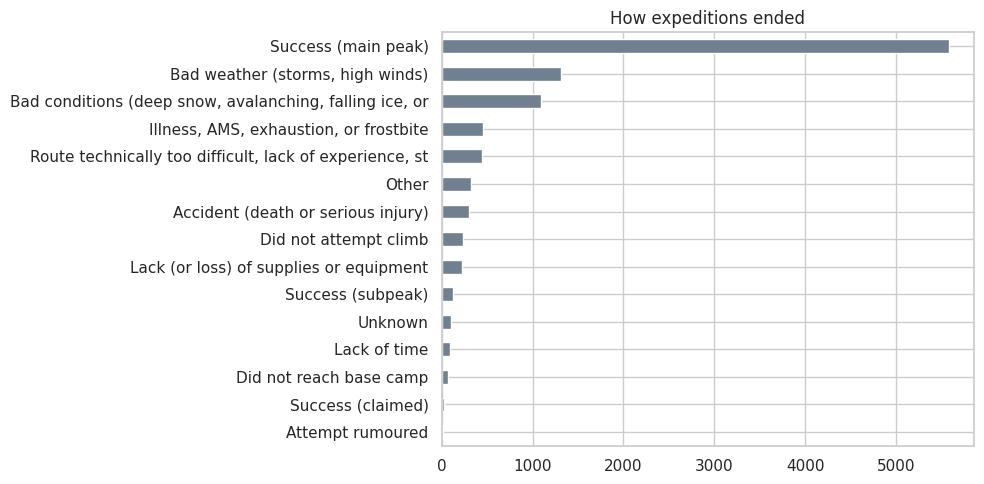

In [17]:
reasons = exp_c.termination_reason.value_counts()
reasons.index = [r[:55] for r in reasons.index]
reasons.sort_values().plot.barh(figsize=(10, 5), color='slategray', title='How expeditions ended')
plt.tight_layout(); plt.show()

,expeditions,success_rate,member_deaths,avg_team
peak_name,,,,
Everest,2149,0.62,186,7.11
Ama Dablam,1366,0.68,26,5.01
Cho Oyu,1332,0.63,42,5.53
Manaslu,632,0.55,69,5.43
Lhotse,429,0.58,17,4.83
Dhaulagiri I,383,0.43,63,5.85
Makalu,356,0.43,30,5.69
Baruntse,308,0.40,6,5.92
Pumori,265,0.48,33,6.09


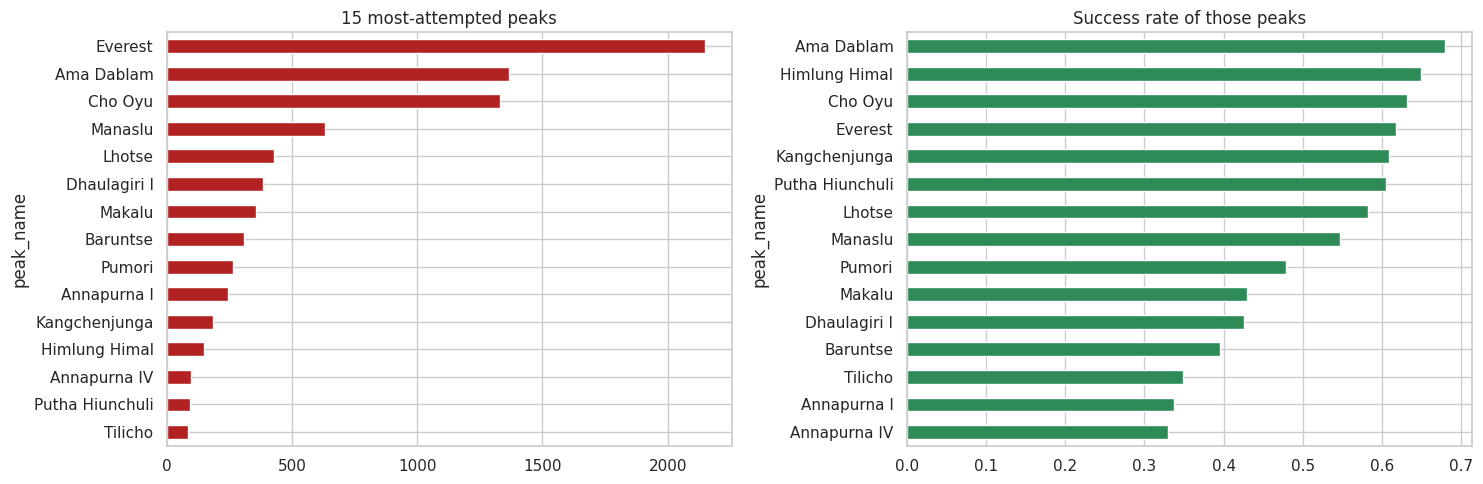

In [18]:
top = exp_c.groupby('peak_name').agg(expeditions=('exp_key', 'size'), success_rate=('success', 'mean'),
                                        member_deaths=('member_deaths', 'sum'),
                                        avg_team=('members', 'mean')).sort_values('expeditions', ascending=False).head(15)
display(top.round(2))
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
top.expeditions.sort_values().plot.barh(ax=ax[0], color='firebrick', title='15 most-attempted peaks')
top.success_rate.sort_values().plot.barh(ax=ax[1], color='seagreen', title='Success rate of those peaks')
plt.tight_layout(); plt.show()

In [19]:
# agencies: who runs the most expeditions?
ag = exp_c.groupby('trekking_agency').agg(expeditions=('exp_key', 'size'), success_rate=('success', 'mean')).sort_values('expeditions', ascending=False)
print('Distinct agencies:', len(ag))
ag.head(10).round(2)

Distinct agencies: 827


,expeditions,success_rate
trekking_agency,,
Asian Trekking,853,0.54
Thamserku Trekking,707,0.52
Himalayan Guides,374,0.70
Seven Summit Treks,313,0.65
Cosmo Treks,293,0.52
Monterosa Treks,243,0.46
Cho Oyu Trekking,199,0.55
Arun Treks,148,0.66
Prestige Adventure,147,0.57


## 6. Members

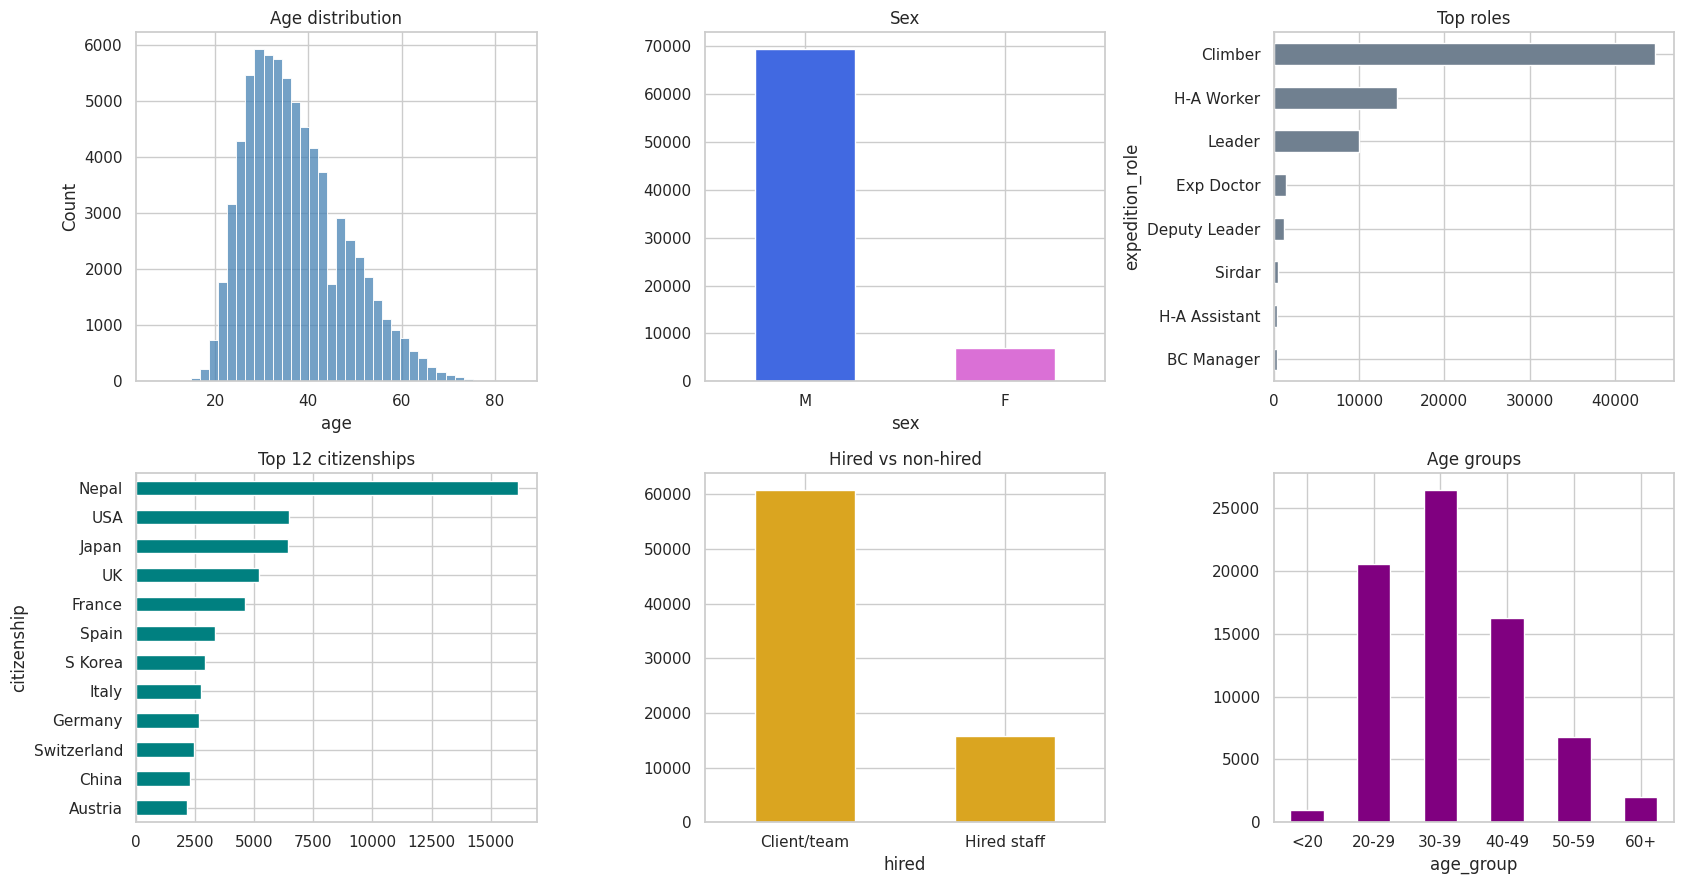

In [20]:
fig, ax = plt.subplots(2, 3, figsize=(17, 9))
sns.histplot(mem_c.age.dropna(), bins=40, ax=ax[0, 0], color='steelblue'); ax[0, 0].set(title='Age distribution')
mem_c.sex.value_counts().plot.bar(ax=ax[0, 1], rot=0, color=['royalblue', 'orchid']); ax[0, 1].set(title='Sex')
mem_c.expedition_role.value_counts().head(8).sort_values().plot.barh(ax=ax[0, 2], color='slategray'); ax[0, 2].set(title='Top roles')
mem_c.citizenship.value_counts().head(12).sort_values().plot.barh(ax=ax[1, 0], color='teal'); ax[1, 0].set(title='Top 12 citizenships')
mem_c.hired.value_counts().rename({False: 'Client/team', True: 'Hired staff'}).plot.bar(ax=ax[1, 1], rot=0, color='goldenrod'); ax[1, 1].set(title='Hired vs non-hired')
mem_c.age_group.value_counts().sort_index().plot.bar(ax=ax[1, 2], rot=0, color='purple'); ax[1, 2].set(title='Age groups')
plt.tight_layout(); plt.show()

In [21]:
print('Share female :', round((mem_c.sex == 'F').mean(), 3))
print('Share hired  :', round(mem_c.hired.mean(), 3))
print('Success     :', round(mem_c.success.mean(), 3))
print('Died        :', round(mem_c.died.mean(), 4))
print('Injured     :', round(mem_c.injured.mean(), 4))
print('Used oxygen :', round(mem_c.oxygen_used.mean(), 3))
print('Solo climbs :', mem_c.solo.sum())

Share female : 0.092
Share hired  : 0.206
Success     : 0.382
Died        : 0.0145
Injured     : 0.0224
Used oxygen : 0.238
Solo climbs : 121


,n,success,death_rate
age_group,,,
<20,575,0.4087,0.0104
20-29,14923,0.3064,0.0155
30-39,20891,0.3284,0.0133
40-49,14138,0.3306,0.0106
50-59,6521,0.2840,0.0095
60+,1990,0.2101,0.0101


,n,success,death_rate
sex,,,
F,7012,0.3266,0.0070
M,53774,0.3127,0.0137


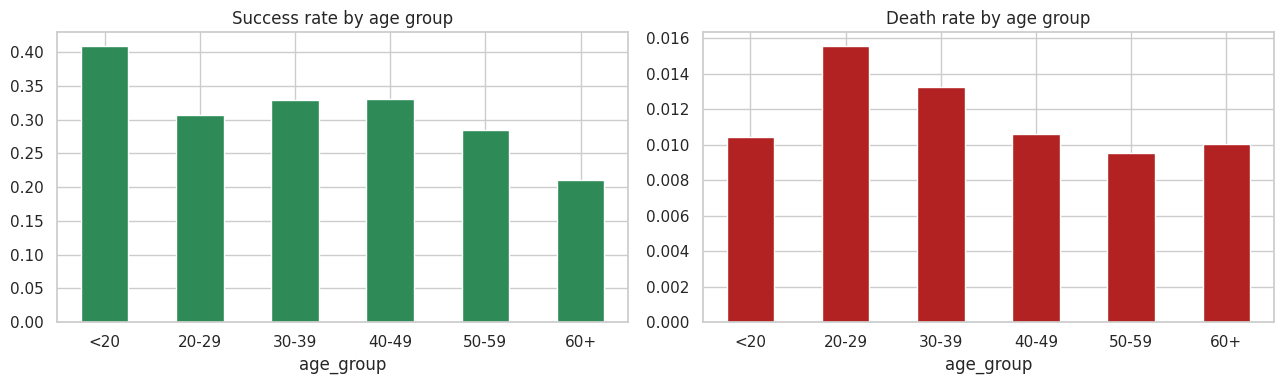

In [22]:
# non-hired members only (clients / team climbers) - success and death by group
clients = mem_c[~mem_c.hired]
by_age = clients.groupby('age_group').agg(n=('member_id', 'size'), success=('success', 'mean'), death_rate=('died', 'mean'))
by_sex = clients.groupby('sex').agg(n=('member_id', 'size'), success=('success', 'mean'), death_rate=('died', 'mean'))
display(by_age.round(4)); display(by_sex.round(4))
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
by_age.success.plot.bar(ax=ax[0], rot=0, color='seagreen', title='Success rate by age group')
by_age.death_rate.plot.bar(ax=ax[1], rot=0, color='firebrick', title='Death rate by age group')
plt.tight_layout(); plt.show()

In [23]:
# nationality: volume vs success (countries with 1000+ members, non-hired)
nat = clients.groupby('citizenship').agg(n=('member_id', 'size'), success=('success', 'mean'), death_rate=('died', 'mean'))
nat = nat[nat.n >= 1000].sort_values('success', ascending=False)
nat.round(3)

,n,success,death_rate
citizenship,,,
China,1722,0.553,0.009
Nepal,1064,0.483,0.007
Russia,1335,0.445,0.020
India,1937,0.424,0.020
USA,6448,0.330,0.007
Germany,2661,0.328,0.012
Switzerland,2458,0.326,0.010
Australia,1416,0.322,0.015
Japan,6432,0.298,0.019


## 7. Trends over time

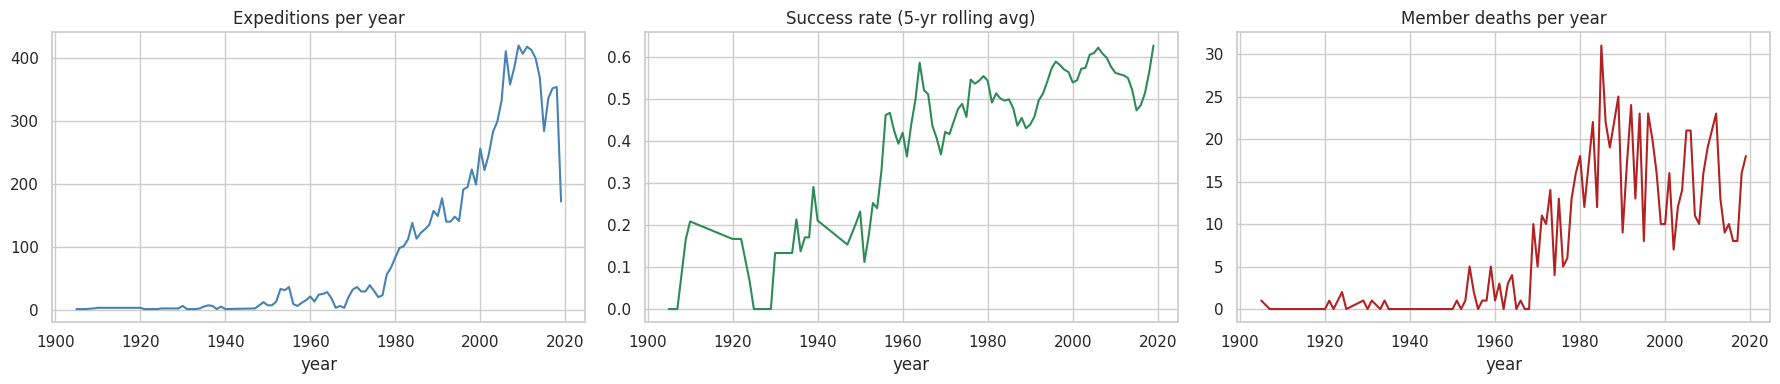

In [24]:
yr = exp_c.groupby('year').agg(expeditions=('exp_key', 'size'), success=('success', 'mean'), deaths=('member_deaths', 'sum'))
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
yr.expeditions.plot(ax=ax[0], color='steelblue', title='Expeditions per year')
yr.success.rolling(5, min_periods=1).mean().plot(ax=ax[1], color='seagreen', title='Success rate (5-yr rolling avg)')
yr.deaths.plot(ax=ax[2], color='firebrick', title='Member deaths per year')
plt.tight_layout(); plt.show()

In [25]:
dec = exp_c.groupby('decade').agg(expeditions=('exp_key', 'size'), success=('success', 'mean'),
                                    oxygen=('oxygen_used', 'mean'), avg_team=('members', 'mean'),
                                    avg_staff=('hired_staff', 'mean'), deaths=('member_deaths', 'sum'))
dec.round(2)

,expeditions,success,oxygen,avg_team,avg_staff,deaths
decade,,,,,,
1900,4,0.25,0.00,2.25,1.00,1
1910,3,0.33,0.00,1.00,0.00,0
1920,10,0.00,0.20,5.10,11.90,4
1930,34,0.35,0.09,4.47,8.03,2
1940,15,0.33,0.00,3.53,1.73,0
1950,168,0.38,0.14,5.10,4.48,16
1960,161,0.54,0.09,6.14,5.99,22
1970,361,0.52,0.19,9.71,6.05,97
1980,1187,0.46,0.15,8.44,2.57,200


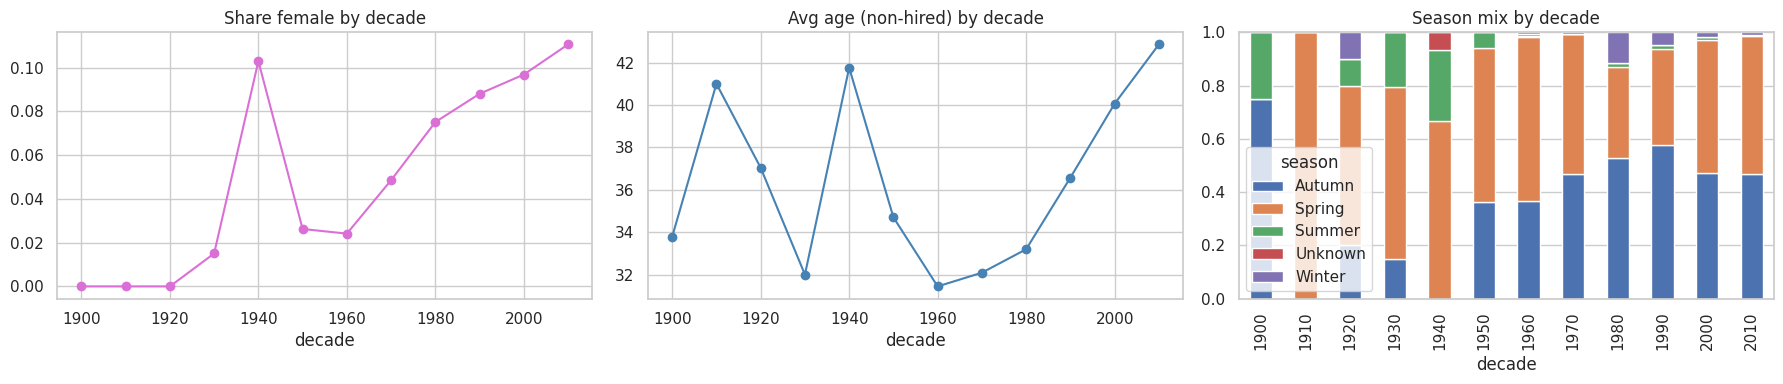

In [26]:
# who is climbing? share of female members and average age over time
fem = mem_c.groupby('decade').apply(lambda d: (d.sex == 'F').mean())
age = mem_c[~mem_c.hired].groupby('decade').age.mean()
season_dec = pd.crosstab(exp_c.decade, exp_c.season, normalize='index')
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
fem.plot(ax=ax[0], marker='o', color='orchid', title='Share female by decade')
age.plot(ax=ax[1], marker='o', color='steelblue', title='Avg age (non-hired) by decade')
season_dec.plot.bar(stacked=True, ax=ax[2], title='Season mix by decade')
plt.tight_layout(); plt.show()

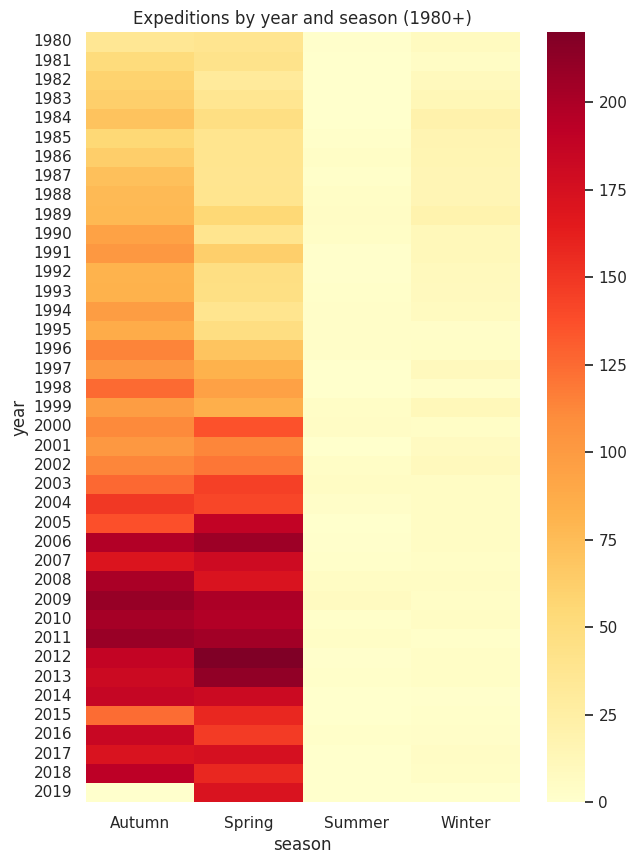

In [27]:
# heatmap: expeditions per year-season for recent decades
recent = exp_c[(exp_c.year >= 1980) & exp_c.season.isin(['Spring', 'Autumn', 'Winter', 'Summer'])]
pivot = recent.pivot_table(index='year', columns='season', values='exp_key', aggfunc='count', fill_value=0)
plt.figure(figsize=(7, 10))
sns.heatmap(pivot, cmap='YlOrRd', annot=False)
plt.title('Expeditions by year and season (1980+)')
plt.show()

## 8. Risk & safety

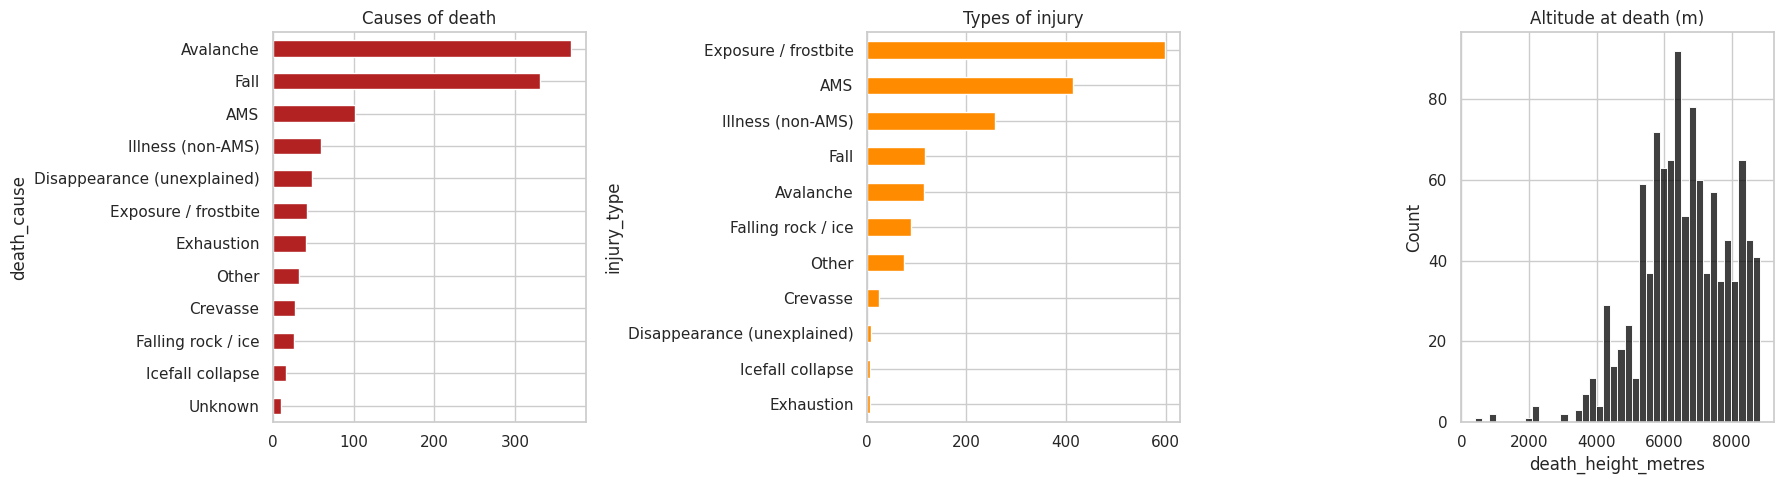

In [28]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
mem_c.death_cause.value_counts().sort_values().plot.barh(ax=ax[0], color='firebrick', title='Causes of death')
mem_c.injury_type.value_counts().sort_values().plot.barh(ax=ax[1], color='darkorange', title='Types of injury')
sns.histplot(mem_c.death_height_metres.dropna(), bins=40, ax=ax[2], color='black'); ax[2].set(title='Altitude at death (m)')
plt.tight_layout(); plt.show()

In [29]:
# hired staff vs everyone else
risk = mem_c.groupby('hired').agg(people=('member_id', 'size'), deaths=('died', 'sum'), death_rate=('died', 'mean'), injury_rate=('injured', 'mean'))
risk.index = ['Non-hired', 'Hired staff']
risk.round(4)

,people,deaths,death_rate,injury_rate
Non-hired,60788,788,0.0130,0.0258
Hired staff,15731,318,0.0202,0.0090


,people,deaths,success,deaths_per_1000
peak_name,,,,
Annapurna I,1669,72,0.18,43.14
Kangchenjunga,1385,51,0.32,36.82
Dhaulagiri I,2592,85,0.21,32.79
Pumori,1780,42,0.29,23.60
Makalu,2405,48,0.24,19.96
Manaslu,4593,85,0.38,18.51
Everest,21813,306,0.46,14.03
Lhotse,2379,21,0.36,8.83
Baruntse,2190,13,0.29,5.94


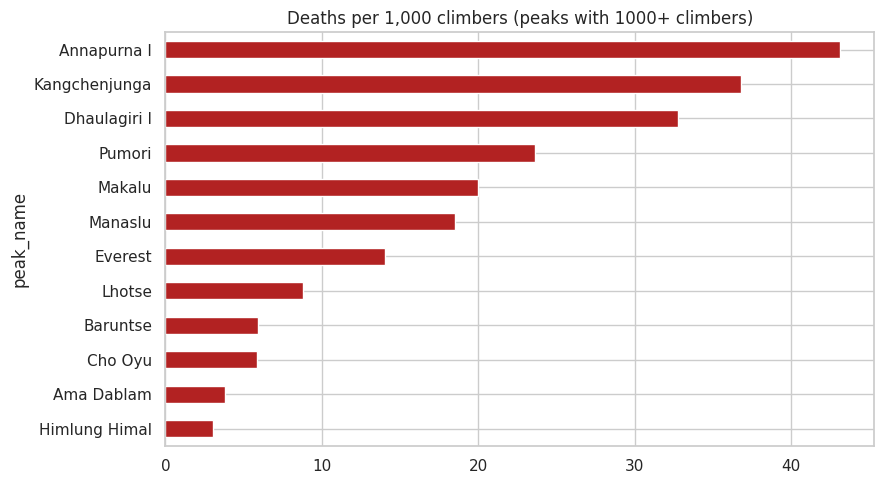

In [30]:
# death rate per MEMBER (not per expedition) for peaks with 1000+ member-trips
pk = mem_c.groupby('peak_name').agg(people=('member_id', 'size'), deaths=('died', 'sum'), success=('success', 'mean'))
pk = pk[pk.people >= 1000]
pk['deaths_per_1000'] = pk.deaths / pk.people * 1000
display(pk.sort_values('deaths_per_1000', ascending=False).round(2))
pk.deaths_per_1000.sort_values().plot.barh(figsize=(9, 5), color='firebrick', title='Deaths per 1,000 climbers (peaks with 1000+ climbers)')
plt.tight_layout(); plt.show()

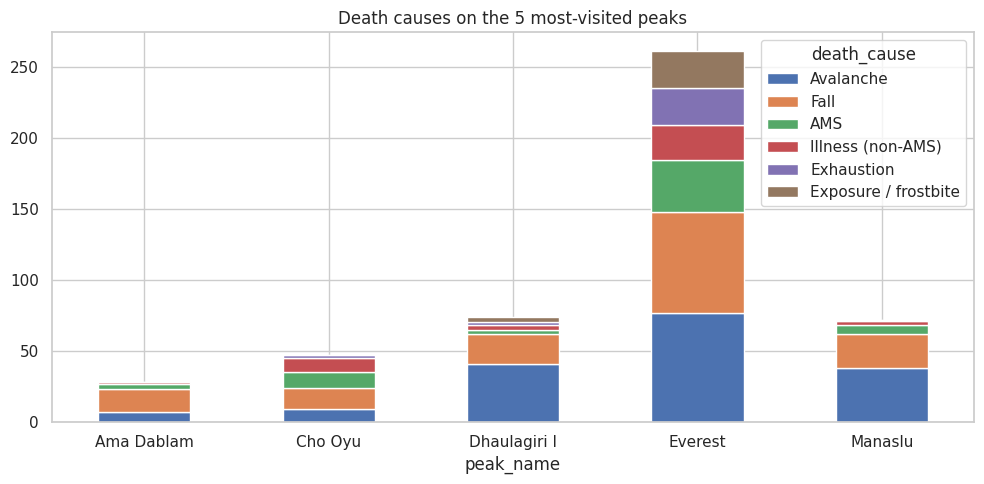

In [31]:
# death cause differs by peak? top causes on the 5 most-visited peaks
top5 = mem_c.peak_name.value_counts().head(5).index
ct = pd.crosstab(mem_c[mem_c.died & mem_c.peak_name.isin(top5)].peak_name, mem_c[mem_c.died].death_cause)
ct = ct.loc[:, ct.sum().sort_values(ascending=False).head(6).index]
ct.plot.bar(stacked=True, figsize=(10, 5), title='Death causes on the 5 most-visited peaks')
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

## 9. Cross-table analysis: peak height & oxygen

In [32]:
merged = exp_c.merge(peaks_c[['peak_id', 'height_metres', 'climbing_status']], on='peak_id', how='left')
merged['height_band'] = pd.cut(merged.height_metres, [0, 6000, 7000, 8000, 9000], labels=['<6000', '6000-6999', '7000-7999', '8000+'])
band = merged.groupby('height_band').agg(expeditions=('exp_key', 'size'), success=('success', 'mean'),
                                         oxygen=('oxygen_used', 'mean'), avg_duration=('duration_days', 'mean'),
                                         deaths=('member_deaths', 'sum'))
band.round(2)

,expeditions,success,oxygen,avg_duration,deaths
height_band,,,,,
<6000,53,0.72,0.08,10.89,1
6000-6999,2555,0.62,0.02,13.58,81
7000-7999,1958,0.41,0.05,19.45,193
8000+,5797,0.57,0.48,33.52,513


size   mean
height_band oxygen_used             
<6000       False          49  0.694
            True            4  1.000
6000-6999   False        2510  0.617
            True           45  0.578
7000-7999   False        1867  0.396
            True           91  0.604
8000+       False        3025  0.360
            True         2772  0.804

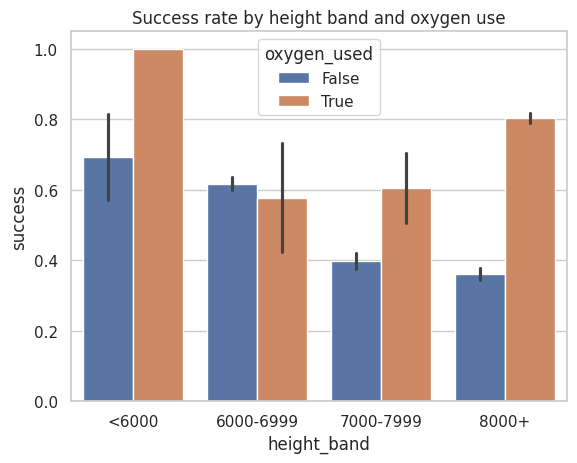

In [33]:
# oxygen effect, controlling for height band (avoids mixing oxygen with peak height)
ox = merged.groupby(['height_band', 'oxygen_used']).success.agg(['size', 'mean']).round(3)
display(ox)
sns.barplot(data=merged, x='height_band', y='success', hue='oxygen_used')
plt.title('Success rate by height band and oxygen use'); plt.show()

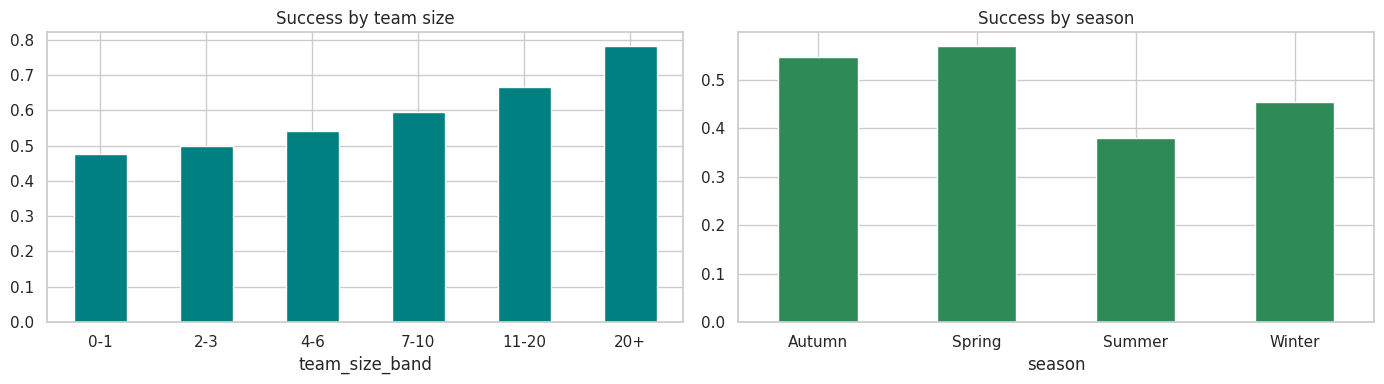

In [34]:
# success by team size and by season
merged['team_size_band'] = pd.cut(merged.members, [-1, 1, 3, 6, 10, 20, 100], labels=['0-1', '2-3', '4-6', '7-10', '11-20', '20+'])
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
merged.groupby('team_size_band').success.mean().plot.bar(ax=ax[0], rot=0, color='teal', title='Success by team size')
merged[merged.season != 'Unknown'].groupby('season').success.mean().plot.bar(ax=ax[1], rot=0, color='seagreen', title='Success by season')
plt.tight_layout(); plt.show()

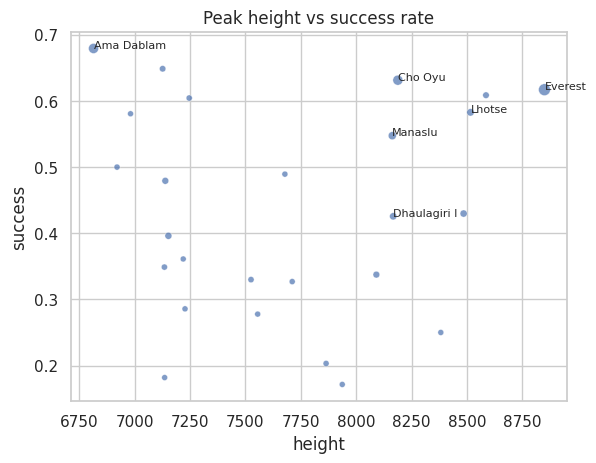

In [35]:
# peak height vs success / deaths per peak (peaks with 30+ expeditions)
pp = merged.groupby('peak_name').agg(n=('exp_key', 'size'), height=('height_metres', 'first'), success=('success', 'mean'))
pp = pp[pp.n >= 30]
sns.scatterplot(data=pp, x='height', y='success', size='n', alpha=0.7, legend=False)
for name, r in pp.nlargest(6, 'n').iterrows():
    plt.annotate(name, (r.height, r.success), fontsize=8)
plt.title('Peak height vs success rate'); plt.show()

## 10. Correlations

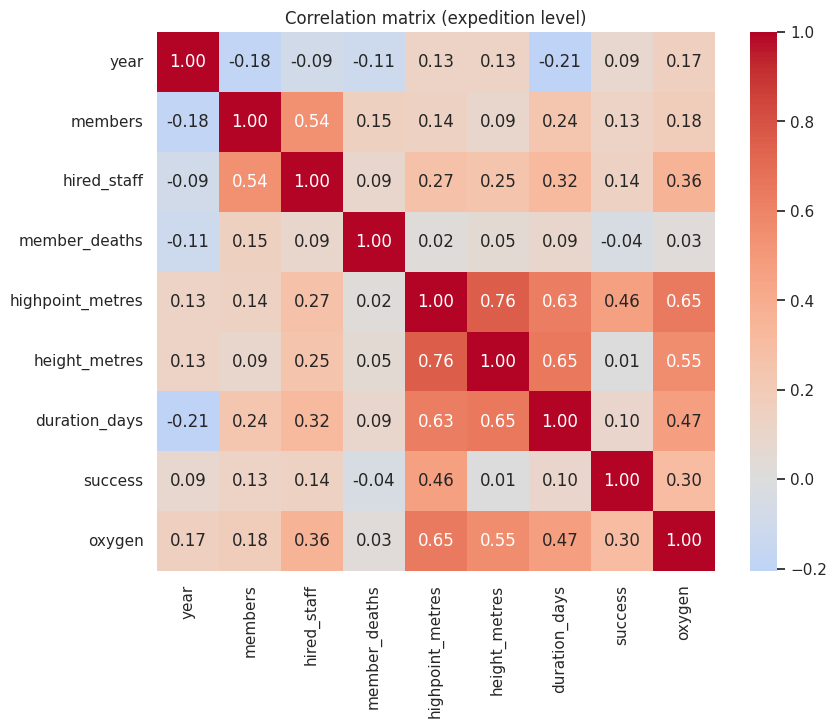

In [36]:
num = merged[['year', 'members', 'hired_staff', 'member_deaths', 'highpoint_metres', 'height_metres', 'duration_days']].copy()
num['success'] = merged.success.astype(int)
num['oxygen'] = merged.oxygen_used.astype(int)
plt.figure(figsize=(9, 7))
sns.heatmap(num.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation matrix (expedition level)')
plt.show()

## 11. Everest deep dive

,expeditions,success,oxygen,avg_team,deaths
decade,,,,,
1920,3,0.00,0.67,11.00,3
1930,5,0.00,0.20,8.60,1
1940,1,0.00,0.00,1.00,0
1950,9,0.22,0.44,11.89,0
1960,16,0.25,0.50,11.50,4
1970,29,0.52,0.76,21.14,10
1980,141,0.31,0.65,14.04,40
1990,331,0.51,0.70,9.00,43
2000,745,0.68,0.81,5.85,42


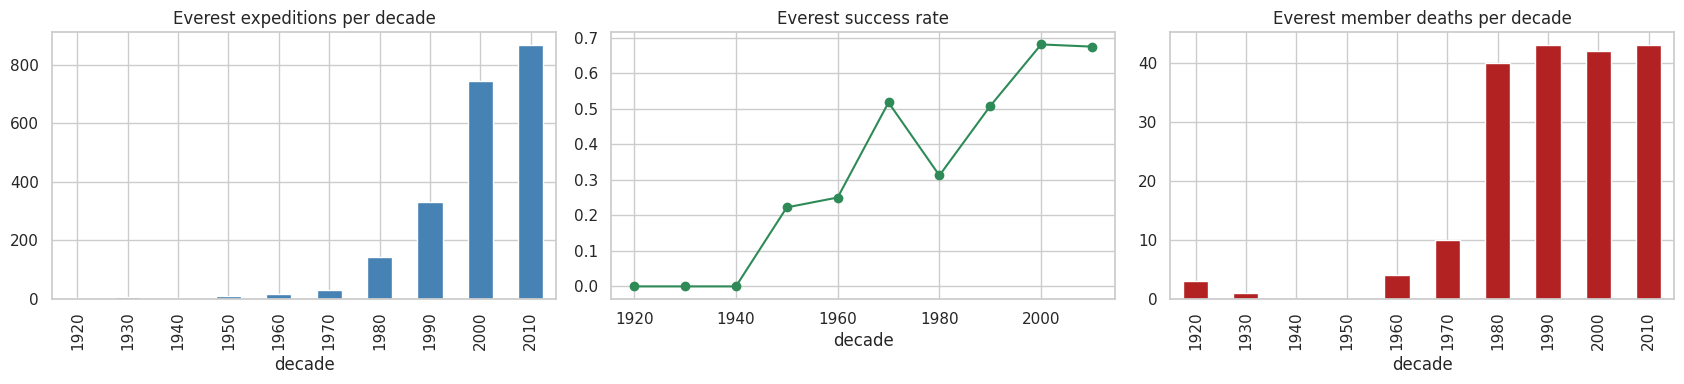

In [37]:
ev = exp_c[exp_c.peak_name == 'Everest']
ev_dec = ev.groupby('decade').agg(expeditions=('exp_key', 'size'), success=('success', 'mean'),
                                  oxygen=('oxygen_used', 'mean'), avg_team=('members', 'mean'), deaths=('member_deaths', 'sum'))
display(ev_dec.round(2))
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
ev_dec.expeditions.plot.bar(ax=ax[0], color='steelblue', title='Everest expeditions per decade')
ev_dec.success.plot(ax=ax[1], marker='o', color='seagreen', title='Everest success rate')
ev_dec.deaths.plot.bar(ax=ax[2], color='firebrick', title='Everest member deaths per decade')
plt.tight_layout(); plt.show()

In [38]:
ev_m = mem_c[mem_c.peak_name == 'Everest']
print('Everest member-trips :', len(ev_m))
print('Deaths              :', ev_m.died.sum(), f'({ev_m.died.mean()*1000:.1f} per 1,000)')
print('Summit success      :', round(ev_m.success.mean(), 3))
print('Share hired staff   :', round(ev_m.hired.mean(), 3))
ev_m[ev_m.died].death_cause.value_counts()

Everest member-trips : 21813
Deaths              : 306 (14.0 per 1,000)
Summit success      : 0.46
Share hired staff   : 0.309


death_cause
Avalanche                      77
Fall                           71
AMS                            36
Exhaustion                     26
Exposure / frostbite           26
Illness (non-AMS)              25
Icefall collapse               15
Crevasse                       11
Disappearance (unexplained)     9
Other                           5
Falling rock / ice              3
Unknown                         2
Name: count, dtype: int64

## 12. Key findings

**Data quality**
- One duplicated `expedition_id` (KANG10101, used in 1910 and 2010), one orphan peak (`SPHU`), one impossible first-ascent year (Sharphu II = 201), 48 expeditions with 0 members, and 11 highpoints above the listed peak height.
- Death counts agree across tables (100%), but headcounts match member rows for only ~66% of expeditions.
- Biggest gaps: member highpoint (~28% missing), trekking agency (~17%), expedition dates (6-23%), age (~5%).

**Expeditions**
- ~55% of expeditions succeed. Activity grew from ~1,200 (1980s) to ~3,500 (2010s); success rose from 46% to ~57-59%.
- Team size fell (avg 9.7 members in the 1970s to 4.8 in the 2010s) while oxygen use rose (19% to 35%).
- Everest, Ama Dablam and Cho Oyu are the most-attempted peaks.

**Oxygen & height**
- Raw oxygen effect looks huge (80% vs 46%), but it is mostly peak height. Within 8000 m+ peaks: 80% with oxygen vs 36% without. Within 7000-7999 m: 60% vs 40%. Below 7000 m oxygen is rarely used and makes no clear difference.

**Members**
- 92% male, 21% hired staff. Nepal is the largest nationality, then USA and Japan.
- Among non-hired climbers, success declines after 50 (21% for 60+) and women have about half the death rate of men (0.7% vs 1.4%).

**Risk**
- Avalanches (369) and falls (331) cause the most deaths; altitude sickness is third (102).
- Hired staff die more often (2.0% vs 1.3%) but are injured less often (0.9% vs 2.6%).
- Per 1,000 climbers, the deadliest big peaks are Annapurna I (43), Kangchenjunga (37) and Dhaulagiri I (33). Everest is 14 per 1,000, with 306 deaths because of its sheer volume.

**Everest**
- Success climbed from ~31% (1980s) to ~67-68% (2000s-2010s) while teams got smaller.

**Caveats**
- Early records are less complete, so the post-1980 growth is partly better record-keeping.
- "Success" here includes main peak, subpeak and claimed summits.
- These are descriptive patterns, not causal claims.